# Tema 2 - Laborator 3: Probabilităţi condiţionate. Formula lui Bayes

Conţinut:
1. Exerciţiul 1: două zaruri (calcul exact + simulare cu 100.000 de aruncări)
2. Exerciţiul 2: filtrarea mesajelor spam
3. Exerciţiul 3: paradoxul lui Simpson (analiză cu `pandas`)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(12)

## Exerciţiul 1: Două zaruri

Se aruncă două zaruri cu rezultatele $X$ şi $Y$. Spaţiul de probabilitate are $36$ de rezultate echiprobabile $(x, y)$.

### 1. $P(X+Y \ge 10 \mid X \text{ par})$

Evenimentul "$X$ par" are $3 \cdot 6 = 18$ rezultate ($X \in \{2,4,6\}$). Dintre acestea, cele cu suma $\ge 10$ sunt:
$(4,6),\ (6,4),\ (6,5),\ (6,6)$, deci $4$ rezultate.

$$P(X+Y\ge 10 \mid X \text{ par}) = \frac{P(X+Y \ge 10,\ X\text{ par})}{P(X \text{ par})} = \frac{4/36}{18/36} = \frac{4}{18} = \frac{2}{9} \approx 0.2222$$

### 2. $P(X+Y \ge 10 \mid \text{cel puţin un zar par})$

Complementul ("ambele impare") are $3\cdot 3 = 9$ rezultate, deci "cel puţin un zar par" are $36 - 9 = 27$ rezultate.

Rezultatele cu suma $\ge 10$ sunt: $(4,6),(5,5),(6,4),(5,6),(6,5),(6,6)$, adică $6$. Dintre ele, $(5,5)$ are ambele zaruri impare, deci rămân $5$ rezultate cu cel puţin un zar par.

$$P(X+Y\ge 10 \mid \text{cel puţin un par}) = \frac{5/36}{27/36} = \frac{5}{27} \approx 0.1852$$

### 3. $P(\text{ambele pare} \mid X+Y = 8)$

Rezultatele cu suma $8$: $(2,6),(3,5),(4,4),(5,3),(6,2)$, adică $5$ rezultate. Cu ambele zaruri pare: $(2,6),(4,4),(6,2)$, adică $3$.

$$P(\text{ambele pare} \mid X+Y=8) = \frac{3}{5} = 0.6$$

### 4. Independenţa evenimentelor $A = \{X+Y \ge 10\}$ şi $B = \{X \text{ par}\}$

$$P(A) = \frac{6}{36} = \frac16, \qquad P(B) = \frac{18}{36} = \frac12, \qquad P(A\cap B) = \frac{4}{36} = \frac19$$

$$P(A)\,P(B) = \frac16\cdot\frac12 = \frac1{12} \neq \frac19 = P(A\cap B)$$

Deoarece $P(A \cap B) \ne P(A)P(B)$, evenimentele $A$ şi $B$ **nu sunt independente**. De fapt $P(A \mid B) = \tfrac29 > \tfrac16 = P(A)$, adică faptul că primul zar e par face suma mare mai probabilă (zarul $6$ este par şi ajută la suma mare).

### Extensie Python: simulare cu 100.000 de aruncări

Generăm $100000$ perechi $(X, Y)$ şi estimăm fiecare probabilitate condiţionată ca raport între numărul de cazuri favorabile (în care se întâmplă ambele evenimente) şi numărul de cazuri în care se întâmplă condiţia.

In [2]:
n = 100_000
X = np.random.randint(1, 7, size=n)   # primul zar
Y = np.random.randint(1, 7, size=n)   # al doilea zar
S = X + Y

def prob_cond(eveniment, conditie):
    # P(eveniment | conditie) estimata ca raport de frecvente
    return (eveniment & conditie).sum() / conditie.sum()

X_par = (X % 2 == 0)
Y_par = (Y % 2 == 0)

# 1. P(S >= 10 | X par)
sim1 = prob_cond(S >= 10, X_par)
# 2. P(S >= 10 | cel putin un zar par)
sim2 = prob_cond(S >= 10, X_par | Y_par)
# 3. P(ambele pare | S = 8)
sim3 = prob_cond(X_par & Y_par, S == 8)

exact = {"1": 2/9, "2": 5/27, "3": 3/5}
sim = {"1": sim1, "2": sim2, "3": sim3}
nume = {
    "1": "P(S>=10 | X par)",
    "2": "P(S>=10 | cel putin un par)",
    "3": "P(ambele pare | S=8)",
}

tabel = pd.DataFrame({
    "probabilitate": [nume[k] for k in exact],
    "exact": [exact[k] for k in exact],
    "simulare": [sim[k] for k in exact],
})
tabel["diferenta"] = (tabel["exact"] - tabel["simulare"]).abs()
print(tabel.round(4).to_string(index=False))

              probabilitate  exact  simulare  diferenta
           P(S>=10 | X par) 0.2222    0.2235     0.0013
P(S>=10 | cel putin un par) 0.1852    0.1861     0.0010
       P(ambele pare | S=8) 0.6000    0.6010     0.0010


In [3]:
# 4. Independenta: comparam P(A and B) cu P(A) * P(B)
A = (S >= 10)
B = X_par

pA, pB, pAB = A.mean(), B.mean(), (A & B).mean()
print(f"P(A)        ~ {pA:.4f}   (exact 1/6  = {1/6:.4f})")
print(f"P(B)        ~ {pB:.4f}   (exact 1/2  = {1/2:.4f})")
print(f"P(A si B)   ~ {pAB:.4f}   (exact 1/9  = {1/9:.4f})")
print(f"P(A) * P(B) ~ {pA * pB:.4f}   (exact 1/12 = {1/12:.4f})")
print()
print("P(A si B) != P(A) * P(B)  =>  A si B NU sunt independente")

P(A)        ~ 0.1663   (exact 1/6  = 0.1667)
P(B)        ~ 0.5017   (exact 1/2  = 0.5000)
P(A si B)   ~ 0.1121   (exact 1/9  = 0.1111)
P(A) * P(B) ~ 0.0834   (exact 1/12 = 0.0833)

P(A si B) != P(A) * P(B)  =>  A si B NU sunt independente


Valorile din simulare sunt apropiate de cele exacte (diferenţe de ordinul miimilor), iar $P(A \cap B)$ rămâne clar diferită de $P(A)\,P(B)$, deci simularea confirmă dependenţa.

## Exerciţiul 2: Filtrarea mesajelor spam

Notăm: $S$ = "mesajul este spam", $L$ = "mesajul este legitim", $O$ = "conţine cuvântul *ofertă*", $G$ = "conţine cuvântul *gratuit*". Din enunţ:

$$P(S) = 0.3,\quad P(L) = 0.7,\quad P(O \mid S) = 0.8,\quad P(O \mid L) = 0.15$$
$$P(G \mid S) = 0.6,\quad P(G \mid L) = 0.1$$

### 1. $P(S \mid O)$

Probabilitatea totală a cuvântului "ofertă":

$$P(O) = P(O\mid S)P(S) + P(O\mid L)P(L) = 0.8\cdot 0.3 + 0.15\cdot 0.7 = 0.24 + 0.105 = 0.345$$

Din formula lui Bayes:

$$P(S \mid O) = \frac{P(O\mid S)\,P(S)}{P(O)} = \frac{0.24}{0.345} = \frac{16}{23} \approx 0.6957$$

### 2. $P(S \mid O \cap G)$ cu independenţă condiţionată

Presupunem că, **dată clasa** (spam sau legitim), apariţiile celor două cuvinte sunt independente:

$$P(O \cap G \mid S) = P(O\mid S)\,P(G\mid S) = 0.8 \cdot 0.6 = 0.48$$
$$P(O \cap G \mid L) = P(O\mid L)\,P(G\mid L) = 0.15 \cdot 0.1 = 0.015$$

$$P(O\cap G) = 0.48 \cdot 0.3 + 0.015 \cdot 0.7 = 0.144 + 0.0105 = 0.1545$$

$$P(S \mid O\cap G) = \frac{0.144}{0.1545} = \frac{96}{103} \approx 0.9320$$

Deci un mesaj cu ambele cuvinte este spam cu probabilitate de aproximativ $93\%$.

### 3. De ce poate fi nerealistă independenţa condiţionată?

Ipoteza spune că, ştiind că mesajul este spam, faptul că apare "ofertă" nu ne spune nimic despre apariţia lui "gratuit". În realitate, cuvintele dintr-un mesaj sunt corelate:

- Spamurile sunt scrise pe şabloane ("ofertă **gratuită** doar azi"), deci cuvintele de tip promoţional apar împreună mai des decât ar sugera produsul probabilităţilor.
- Există subtipuri de spam (farmacie, investiţii, loterii), iar cuvintele depind de subtip, nu doar de faptul că mesajul e spam.
- Ca urmare, $P(O\cap G \mid S) \ne P(O\mid S)\,P(G\mid S)$ în general, iar produsul **numără de două ori aceeaşi informaţie**. Probabilitatea calculată ($93\%$) tinde să fie **supraestimată** (prea sigură), mai ales când se combină multe cuvinte corelate.

Cu toate astea, modelul (numit *Naive Bayes*) funcţionează surprinzător de bine în practică pentru clasificare, chiar dacă probabilităţile exacte nu sunt corecte.

### 4. Regulă de clasificare

Clasificăm mesajul ca **spam** dacă probabilitatea a posteriori depăşeşte un prag $\tau$:

$$\text{spam} \iff P(S \mid \text{cuvinte}) \ge \tau$$

- Pentru erori simetrice, $\tau = 0.5$. Echivalent, comparăm $P(\text{cuvinte}\mid S)P(S)$ cu $P(\text{cuvinte}\mid L)P(L)$ şi alegem clasa mai probabilă.
- Pentru e-mail, este mai grav să pierdem un mesaj legitim (fals pozitiv) decât să primim un spam (fals negativ), deci se alege un prag mai mare, de exemplu $\tau = 0.9$, şi se trimit în *Spam* doar mesajele pentru care suntem foarte siguri.

Mai jos calculăm probabilitatea de spam pentru toate cele patru combinaţii de cuvinte şi aplicăm regula.

In [4]:
p_S, p_L = 0.3, 0.7
p_o = {"S": 0.8, "L": 0.15}   # P(oferta | clasa)
p_g = {"S": 0.6, "L": 0.10}   # P(gratuit | clasa)

# 1. P(spam | oferta)
p_oferta = p_o["S"] * p_S + p_o["L"] * p_L
print(f"1. P(oferta) = {p_oferta:.4f}")
print(f"   P(spam | oferta) = {p_o['S'] * p_S / p_oferta:.4f}  (16/23 = {16/23:.4f})")

# 2. P(spam | oferta si gratuit), cu independenta conditionata
num = p_o["S"] * p_g["S"] * p_S
den = num + p_o["L"] * p_g["L"] * p_L
print(f"2. P(spam | oferta si gratuit) = {num / den:.4f}  (96/103 = {96/103:.4f})")

1. P(oferta) = 0.3450
   P(spam | oferta) = 0.6957  (16/23 = 0.6957)
2. P(spam | oferta si gratuit) = 0.9320  (96/103 = 0.9320)


In [5]:
def p_spam(are_oferta, are_gratuit):
    # probabilitatea de spam, stiind ce cuvinte apar / nu apar in mesaj
    def verosim(clasa):
        v = p_o[clasa] if are_oferta else 1 - p_o[clasa]
        v *= p_g[clasa] if are_gratuit else 1 - p_g[clasa]
        return v
    spam = verosim("S") * p_S
    leg = verosim("L") * p_L
    return spam / (spam + leg)

def clasifica(are_oferta, are_gratuit, prag=0.5):
    return "SPAM" if p_spam(are_oferta, are_gratuit) >= prag else "legitim"

randuri = []
for o in (True, False):
    for g in (True, False):
        p = p_spam(o, g)
        randuri.append({
            "oferta": o, "gratuit": g,
            "P(spam | cuvinte)": round(p, 4),
            "prag 0.5": clasifica(o, g, 0.5),
            "prag 0.9": clasifica(o, g, 0.9),
        })
print(pd.DataFrame(randuri).to_string(index=False))

 oferta  gratuit  P(spam | cuvinte) prag 0.5 prag 0.9
   True     True             0.9320     SPAM     SPAM
   True    False             0.5039     SPAM  legitim
  False     True             0.3770  legitim  legitim
  False    False             0.0429  legitim  legitim


Verificăm rezultatele numerice şi prin simulare: generăm 1.000.000 de mesaje, apoi estimăm probabilitatea de spam printre cele care conţin cuvintele (în simulare, cuvintele sunt generate independent *dată clasa*, exact ipoteza din enunţ).

In [6]:
n = 1_000_000
spam = np.random.rand(n) < p_S
oferta = np.random.rand(n) < np.where(spam, p_o["S"], p_o["L"])
gratuit = np.random.rand(n) < np.where(spam, p_g["S"], p_g["L"])

print(f"P(spam | oferta)            ~ {spam[oferta].mean():.4f}  (teoretic {16/23:.4f})")
print(f"P(spam | oferta si gratuit) ~ {spam[oferta & gratuit].mean():.4f}  (teoretic {96/103:.4f})")

P(spam | oferta)            ~ 0.6954  (teoretic 0.6957)
P(spam | oferta si gratuit) ~ 0.9321  (teoretic 0.9320)


## Exerciţiul 3: Paradoxul lui Simpson

Datele (promovaţi din total evaluaţi):

| Program | Disciplina A | Disciplina B |
|---|---|---|
| Programul 1 | 81 din 90 | 19 din 20 |
| Programul 2 | 1 din 10 | 16 din 80 |

### 1. Rata de promovare pe disciplină şi program

$$\text{Programul 1: } A: \tfrac{81}{90} = 0.90, \qquad B: \tfrac{19}{20} = 0.95$$
$$\text{Programul 2: } A: \tfrac{1}{10} = 0.10, \qquad B: \tfrac{16}{80} = 0.20$$

### 2. Care disciplină are rata mai mare în fiecare program?

În **ambele** programe, disciplina **B** are rata de promovare mai mare ($0.95 > 0.90$ în Programul 1 şi $0.20 > 0.10$ în Programul 2).

### 3. Rata globală de promovare

$$A: \frac{81 + 1}{90 + 10} = \frac{82}{100} = 0.82, \qquad B: \frac{19 + 16}{20 + 80} = \frac{35}{100} = 0.35$$

### 4. De ce se inversează ordinea?

Agregat, disciplina **A** pare mult mai uşoară ($0.82$ vs. $0.35$), deşi în fiecare program B are rata mai mare. Cauza este că **programul de studiu este o variabilă ascunsă** (de confuzie), iar grupurile au dimensiuni foarte diferite:

- Programul 1 are rate mari la ambele discipline, iar **majoritatea** studenţilor la A vin din Programul 1 ($90$ din $100$).
- Programul 2 are rate mici, iar **majoritatea** studenţilor la B vin din Programul 2 ($80$ din $100$).

Rata globală este o medie ponderată a ratelor din programe, iar **ponderile diferă** între discipline. A "moşteneşte" rata mare a Programului 1, iar B este trasă în jos de Programul 2, care are rate mici la ambele discipline.

### 5. În termeni de probabilităţi condiţionate

Notăm $P$ = "student promovat", $D \in \{A, B\}$ = disciplina, $\Pi \in \{1, 2\}$ = programul. Avem

$$P(P \mid D=B, \Pi=\pi) > P(P \mid D=A, \Pi=\pi) \quad \text{pentru } \pi = 1 \text{ şi } \pi = 2,$$

dar

$$P(P \mid D=B) < P(P \mid D=A).$$

Aceasta se poate întâmpla pentru că, din formula probabilităţii totale,

$$P(P \mid D) = \sum_{\pi} P(P \mid D, \Pi=\pi)\; P(\Pi=\pi \mid D)$$

iar ponderile $P(\Pi=\pi \mid D)$ diferă între discipline:

$$P(\Pi=1 \mid D=A) = 0.9,\ \ P(\Pi=1\mid D=B) = 0.2$$

Verificare: $P(P\mid A) = 0.9\cdot 0.9 + 0.1\cdot 0.1 = 0.82$ şi $P(P\mid B) = 0.2\cdot 0.95 + 0.8\cdot 0.2 = 0.35$.

Inegalităţile pe subgrupuri nu se păstrează la agregare când distribuţia variabilei de confuzie diferă între grupurile comparate.

### Verificare cu `pandas` pe datele din enunţ

In [7]:
date = pd.DataFrame({
    "Program": ["Programul 1", "Programul 1", "Programul 2", "Programul 2"],
    "Disciplina": ["A", "B", "A", "B"],
    "Promovati": [81, 19, 1, 16],
    "Total": [90, 20, 10, 80],
})
date["Rata"] = date["Promovati"] / date["Total"]
print("Rata pe program si disciplina:")
print(date.to_string(index=False))

print()
print("Rate pe program (linii) si disciplina (coloane):")
print(date.pivot(index="Program", columns="Disciplina", values="Rata").round(3))

print()
glob = date.groupby("Disciplina")[["Promovati", "Total"]].sum()
glob["Rata globala"] = glob["Promovati"] / glob["Total"]
print("Rata globala pe disciplina:")
print(glob)

print()
# ponderile P(Program | Disciplina): de aici vine paradoxul
pond = date.pivot(index="Program", columns="Disciplina", values="Total")
print("P(Program | Disciplina) = ponderile din media globala:")
print((pond / pond.sum()).round(3))

Rata pe program si disciplina:
    Program Disciplina  Promovati  Total  Rata
Programul 1          A         81     90  0.90
Programul 1          B         19     20  0.95
Programul 2          A          1     10  0.10
Programul 2          B         16     80  0.20

Rate pe program (linii) si disciplina (coloane):
Disciplina     A     B
Program               
Programul 1  0.9  0.95
Programul 2  0.1  0.20

Rata globala pe disciplina:
            Promovati  Total  Rata globala
Disciplina                                
A                  82    100          0.82
B                  35    100          0.35

P(Program | Disciplina) = ponderile din media globala:
Disciplina     A    B
Program              
Programul 1  0.9  0.2
Programul 2  0.1  0.8


### Extensie Python: exemplu propriu de paradox Simpson

Comparăm două tratamente, **X** şi **Y**, aplicate în cazuri **uşoare** şi **grave**. Tratamentul X este dat mai ales cazurilor uşoare, iar Y mai ales celor grave.

| Gravitate | Tratament X | Tratament Y |
|---|---|---|
| Uşoară | 85 din 100 | 9 din 10 |
| Gravă | 3 din 10 | 40 din 100 |

Construim datele într-un `DataFrame` şi arătăm paradoxul: Y e mai bun în **fiecare** categorie, dar X pare mai bun **global**.

In [8]:
exemplu = pd.DataFrame({
    "Gravitate": ["Usoara", "Usoara", "Grava", "Grava"],
    "Tratament": ["X", "Y", "X", "Y"],
    "Vindecati": [85, 9, 3, 40],
    "Total": [100, 10, 10, 100],
})
exemplu["Rata"] = exemplu["Vindecati"] / exemplu["Total"]

print("Pe categorii de gravitate:")
print(exemplu.pivot(index="Gravitate", columns="Tratament", values="Rata").round(3))

print()
total = exemplu.groupby("Tratament")[["Vindecati", "Total"]].sum()
total["Rata globala"] = total["Vindecati"] / total["Total"]
print("Global (date agregate):")
print(total.round(3))

# verificam ca e intr-adevar paradox Simpson
pivot = exemplu.pivot(index="Gravitate", columns="Tratament", values="Rata")
y_mai_bun_peste_tot = (pivot["Y"] > pivot["X"]).all()
x_mai_bun_global = total.loc["X", "Rata globala"] > total.loc["Y", "Rata globala"]
print()
print("Y e mai bun in fiecare categorie:", y_mai_bun_peste_tot)
print("X e mai bun global:              ", x_mai_bun_global)

Pe categorii de gravitate:
Tratament     X    Y
Gravitate           
Grava      0.30  0.4
Usoara     0.85  0.9

Global (date agregate):
           Vindecati  Total  Rata globala
Tratament                                
X                 88    110         0.800
Y                 49    110         0.445

Y e mai bun in fiecare categorie: True
X e mai bun global:               True


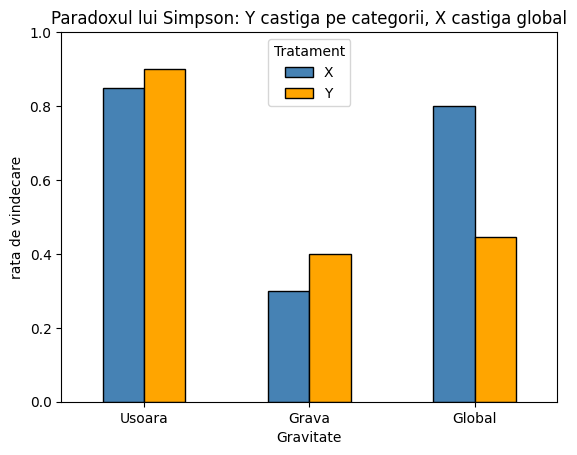

In [9]:
# grafic: ratele pe categorii vs. rata globala
pivot = exemplu.pivot(index="Gravitate", columns="Tratament", values="Rata")
pivot.loc["Global"] = total["Rata globala"]
pivot = pivot.loc[["Usoara", "Grava", "Global"]]

pivot.plot(kind="bar", rot=0, color=["steelblue", "orange"], edgecolor="black")
plt.ylabel("rata de vindecare")
plt.title("Paradoxul lui Simpson: Y castiga pe categorii, X castiga global")
plt.ylim(0, 1)
plt.show()

In [10]:
# explicatia: cum sunt distribuite cazurile intre tratamente
distributie = exemplu.pivot(index="Gravitate", columns="Tratament", values="Total")
print("P(Gravitate | Tratament):")
print((distributie / distributie.sum()).round(3))

P(Gravitate | Tratament):
Tratament      X      Y
Gravitate              
Grava      0.091  0.909
Usoara     0.909  0.091


Tratamentul X este aplicat în $100/110 \approx 91\%$ din cazuri uşoare (care se vindecă uşor oricum), iar Y în $100/110 \approx 91\%$ din cazuri grave. Rata globală a lui X este umflată de faptul că tratează în principal pacienţi uşori, deşi în fiecare categorie Y este mai bun. Concluzia corectă se obţine **stratificând după gravitate** (variabila de confuzie), nu comparând ratele globale.